In [ ]:
import numpy as np
from base.iterative_section_minimiser import mesh_intersect
from stl import Mesh
import base.geometry as geom
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from base.utils import find_neighbours_with_knn
from os.path import exists
import skgstat as skg
import geone


Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


## Riesengang passage / Hölloch

Riesengang passage is a > 400 m rectilinear passage scanned with Leica BLK2GO. After making a mesh of the passage's point cloud, we perform the analysis of its geometric parameters.  

In [2]:
# set up a global conduit name. 
conduit_name = "Riesengang"

# loading the data.
mesh_filepath = f"F:ScanLeica/conduits_for_experiments/Hoelloch/Riesengang.stl"
mesh_data = Mesh.from_file(mesh_filepath)

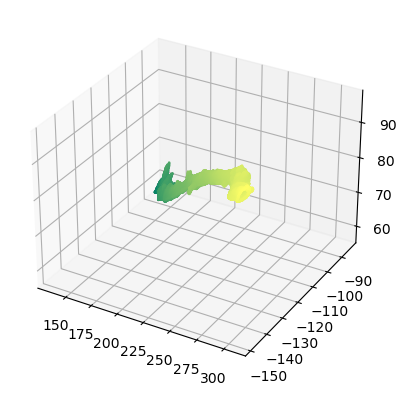

In [3]:
fig = plt.figure() 

ax = fig.add_subplot(projection="3d")
ax.scatter(*mesh_data.vectors[::50, 1, [0, 1, 2]].T, s=0.5, c = mesh_data.vectors[::50, 1, 2], cmap = "summer")
#ax.set_ylim(-25, 25)
#ax.set_zlim(-25, 25)

In [4]:
from base.LBC_centreline import return_LBC_centreline

In [5]:
keep_centreline = True
adj_triangles_filepath = mesh_filepath[:-4] + "_adjacent_triangles.txt"

if exists(adj_triangles_filepath) and keep_centreline == True:
    adj_triangles = np.loadtxt(adj_triangles_filepath)
else:
    adj_triangles = find_neighbours_with_knn(mesh_data)
    np.savetxt(adj_triangles_filepath, adj_triangles)

In [6]:
lbc_args = dict(init_attraction = 1, init_contraction = 0.5, down_sample = 0.7)
ct_args = dict(keep=True, keep_centreline=True, centreline_down_sample= 0.7)

In [7]:
LBC_result = return_LBC_centreline(mesh_filepath, adj_triangles_filepath, lbc_args=lbc_args, ct_args=ct_args)

read file in 0.0000s


2025-05-05 11:50:21,517 - PCD #points: 8185


contracted file in 4.7990s


Volume ratio: 1.0. Contraction weights: 614.6126332417471. Attraction weights: 1.0. Progress LBC:  10%| | 2/20 [00:00<02025-05-05 11:50:23,583 - Contraction is Done.
Volume ratio: 1.0. Contraction weights: 614.6126332417471. Attraction weights: 1.0. Progress LBC:  10%| | 2/20 [00:01<0

Contraction is Done.
extracted skeleton in 2.0912s
downsampled the centreline cloud in 0.0030s
there were 0 connected components.
found largest component in 0.0100s
computed minimum spanning tree in 0.0050s
created graph instance of the centreline in  0.0000s
added node coordinates to graph in  0.0010s
found ring 1 with 908 points.
found ring 2 with 880 points.


computed shortest path in  0.3267s


In [8]:
centreline = LBC_result["centreline"]

In [9]:
from base.refine_centreline import refine

In [ ]:
# at each point in the centreline, use its two neighbours to estimate the passage direction. 

vectors = centreline[:-2] - centreline[2:]
norm_vectors = np.linalg.norm(vectors, axis=1)
normed_vectors = vectors / np.expand_dims(norm_vectors, -1)

In [30]:
# sanitisation step  - check if any of the normal vectors need realigning
strong_dev = np.argwhere(np.linalg.norm(np.diff(normed_vectors, axis = 0), axis = 1)>0.5)
if len(strong_dev) == 0:
    print("no cleaning apparently needed.")

no cleaning apparently needed.


## Intersection of plane to Mesh
We compute mesh intersections and return 3D polygonal lines for each of the centreline points. We avoid the start and end point of the centreline. 

In [31]:
sections = [mesh_intersect(mesh_data, P, nP) for P, nP in tqdm(zip(centreline[1:-1], normed_vectors), total= len(normed_vectors))]

100%|████████████████████████████████████████████████████████████████████████████████| 234/234 [02:56<00:00,  1.32it/s]


Plot the sections against the mesh vertices. 

Here we show a plan view of the pointcloud, the centreline, and the sections computed. 

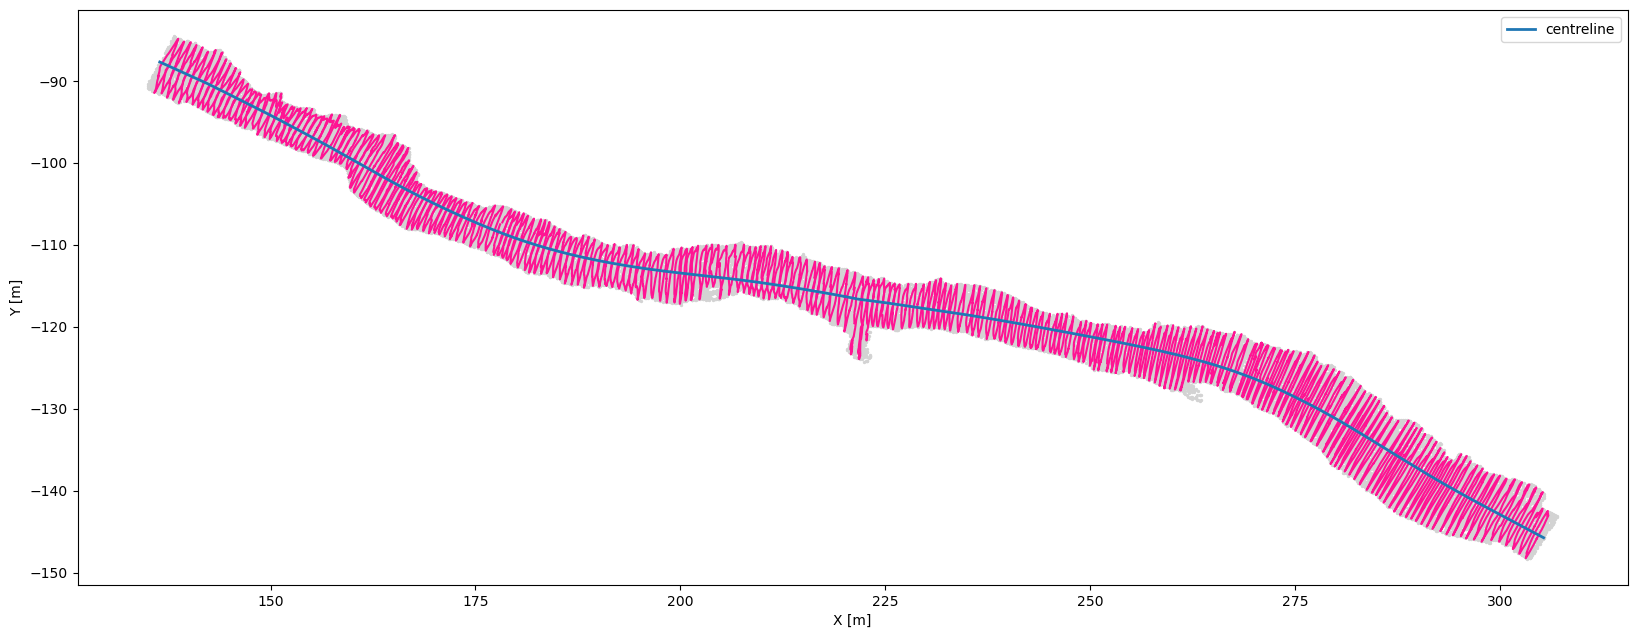

In [32]:
fig, ax = plt.subplots(figsize=(20, 10))

ax.scatter(*mesh_data[::100, [0,1]].T, color = "lightgrey", s = 2)

ax.plot(*centreline[:, [0,1]].T, zorder = 100, lw = 2, label = "centreline")

for section in sections:
    ax.plot(*section[0][:, [0,1]].T, color = "deeppink")

ax.set_aspect("equal")
ax.legend()
ax.set_ylabel("Y [m]")
ax.set_xlabel("X [m]")

plt.savefig(f"./temp/{conduit_name}_plan_sections.pdf")

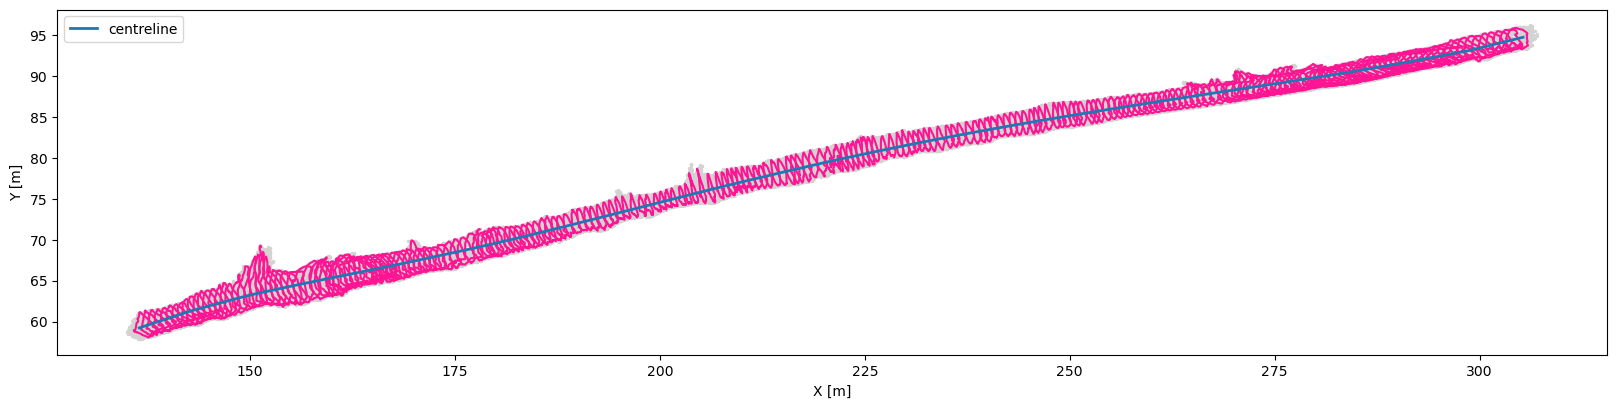

In [33]:
fig, ax = plt.subplots(figsize=(20, 10))

ax.scatter(*mesh_data[::100, [0,2]].T, color = "lightgrey", s = 2)

ax.plot(*centreline[:, [0,2]].T, zorder = 100, lw = 2, label = "centreline")
for section in sections:
    ax.plot(*section[0][:, [0,2]].T, color = "deeppink")

ax.set_aspect("equal")
ax.legend()
ax.set_ylabel("Y [m]")
ax.set_xlabel("X [m]")

plt.savefig(f"./temp/{conduit_name}_profile_sections.pdf")

## From 3D polygon sections to 2D polygons

In [ ]:
sections2d = [geom.to2D(elem[0], elem[5]) for elem in sections]
curvilinear_coords = np.hstack([np.zeros(1), np.cumsum(np.linalg.norm(vectors, axis =1))])

## Perform shape analysis of all the sections

In [56]:
# initialise a list of dictionaries 

descriptors = []

for section, curvilinear_coord in tqdm(zip(sections2d, curvilinear_coords[1:-1]), total=len(sections2d)):
    
    description = geom.describe(section)
    description["curvilinear_coord"] = curvilinear_coord

    descriptors.append(description)

100%|███████████████████████████████████████████████████████████████████████████████▋| 233/234 [00:02<00:00, 78.60it/s]


In [ ]:
dhi = np.array([elem["hydraulic_diameter"] for elem in descriptors])
li = np.diff(curvilinear_coords[1:])

In [ ]:
def equivalent_dh(dhi, li):
    # harmonic mean along the section 
    return np.sum(li)**(1/4) * np.sum(li *dhi**(-4))**(-1/4)

In [61]:
max_chords = np.array([elem["max_chord_length"] for elem in descriptors])

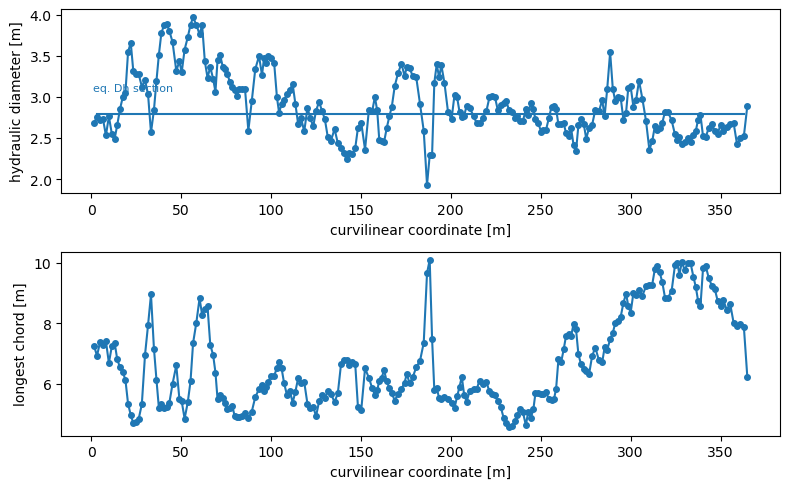

In [128]:

fig, (ax, axchords) = plt.subplots(2, 1, figsize = (8, 5))

ax.plot(curvilinear_coords[1:-1], dhi, "-o", markersize=4)


#plt.plot(curvilinear_coords[1:-1], [elem["hydraulic_diameter"] for elem in descriptors][1:], label = "hydraulic_diameter")
ax.axhline(equivalent_dh(dhi, li), ls = "-", xmin=0.05, xmax=0.95)

ax.text(1,equivalent_dh(dhi, li)*1.1, "eq. Dh section", color = "C0", fontsize = 8)

ax.set_xlabel("curvilinear coordinate [m]")
ax.set_ylabel("hydraulic diameter [m]")


axchords.plot(curvilinear_coords[1:-1], max_chords, "-o", markersize=4)
axchords.set_xlabel("curvilinear coordinate [m]")
axchords.set_ylabel("longest chord [m]")

plt.tight_layout()
plt.savefig(f"./temp/{conduit_name}_hydraulic_diameters.pdf")

In [65]:
np.savetxt(f"./temp/{conduit_name}_dimensions_curvilinear_no_header.txt", np.vstack([curvilinear_coords[1:-1], max_chords, dhi]).T)

Experimental variogram by binning by lag. 

In [66]:
descriptor_keys = [elem for elem in descriptors[0].keys() if elem != "cog" and elem !="ellipse_area" and elem !="ellipse_axes" and elem !="ellipse_eigenvalues"]
print(descriptor_keys)

['area', 'ellipse_aspect_ratio', 'ellipse_rotation', 'perimeter', 'solidity', 'hydraulic_diameter', 'max_chord_length', 'rmax', 'rmin', 'r_average', 'circularity', 'circularity2', 'gravelius_compactness', 'circularity3', 'deviation_from_inscribe_disk', 'deviation_from_circumsribed_disk', 'elongation', 'isoperimetric_deficiency', 'morton_spreading_index', 'circular_variance', 'curvilinear_coord']


In [67]:
m = len(descriptors)
n = len(descriptor_keys)

data = np.zeros((m,n))

In [68]:
# cycle over each descriptor and store to numpy array. 
for c, key in enumerate(descriptor_keys):
    print(key)
    data[:, c] =  [elem[key] for elem in descriptors]

area
ellipse_aspect_ratio
ellipse_rotation
perimeter
solidity
hydraulic_diameter
max_chord_length
rmax
rmin
r_average
circularity
circularity2
gravelius_compactness
circularity3
deviation_from_inscribe_disk
deviation_from_circumsribed_disk
elongation
isoperimetric_deficiency
morton_spreading_index
circular_variance
curvilinear_coord


In [71]:
import pandas as pd

In [72]:
df = pd.DataFrame(data, columns=descriptor_keys)

In [73]:
df.to_csv(f"./temp/{conduit_name}_descriptors.csv")

In [74]:
df.head()

,area,ellipse_aspect_ratio,ellipse_rotation,perimeter,solidity,hydraulic_diameter,max_chord_length,rmax,rmin,r_average,...,circularity2,gravelius_compactness,circularity3,deviation_from_inscribe_disk,deviation_from_circumsribed_disk,elongation,isoperimetric_deficiency,morton_spreading_index,circular_variance,curvilinear_coord
0,11.503631,2.181184,91.664550,17.119047,0.901858,2.687914,7.237662,3.674119,1.301318,2.177511,...,25.475587,24.374557,1.823383,0.462468,3.686561,3.089046,0.493271,0.279607,1.332868e-28,1.647655
1,11.394695,2.121308,93.066550,16.557943,0.906842,2.752684,6.919469,3.645442,1.091485,2.146419,...,24.060801,22.911657,2.339892,0.328460,3.663934,3.149080,0.522276,0.303017,1.178107e-27,3.295313
2,11.670668,2.243539,93.797116,17.202329,0.884835,2.713741,7.366972,3.899275,1.035207,2.203822,...,25.355887,24.435528,2.766662,0.288475,4.092813,3.059517,0.495600,0.273796,2.280193e-28,4.942955
3,11.608282,2.254784,93.762246,16.984244,0.873523,2.733894,7.283222,3.861212,1.089676,2.183613,...,24.849891,23.883807,2.543450,0.321349,4.034867,3.099751,0.505691,0.278632,3.648557e-30,6.590607
4,10.802164,2.437539,94.149819,17.070772,0.873760,2.531148,7.406151,3.918015,1.107451,2.187630,...,26.977120,25.011862,2.537868,0.356688,4.464484,2.873910,0.465816,0.250747,4.726801e-28,8.238262


In [75]:
descriptor = "hydraulic_diameter"
maxlag = 30

In [76]:
V = skg.Variogram(df["curvilinear_coord"], df[descriptor], maxlag=maxlag, bin_func="sturges", estimator="cressie", model="gaussian")

C:\Users\racinet\.conda\envs\PCProcessing\lib\site-packages\skgstat\plotting\variogram_plot.py:123: UserWarning: Matplotlib is currently using module://matplotlib_inline.backend_inline, which is a non-GUI backend, so cannot show the figure.
  fig.show()
C:\Users\racinet\.conda\envs\PCProcessing\lib\site-packages\skgstat\plotting\variogram_plot.py:123: UserWarning: Matplotlib is currently using module://matplotlib_inline.backend_inline, which is a non-GUI backend, so cannot show the figure.
  fig.show()


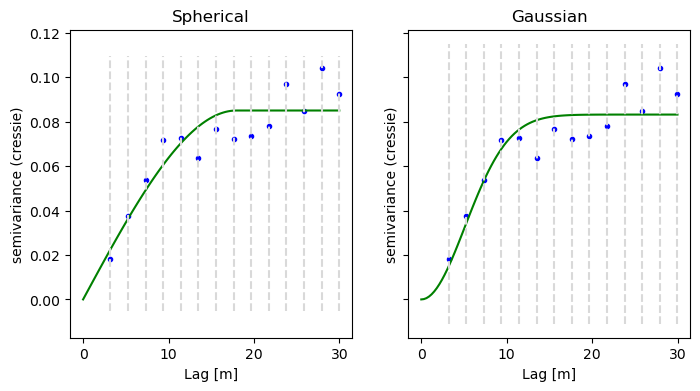

In [77]:
fig, axes = plt.subplots(1, 2, figsize = (8, 4), sharey = True)

axes[0].set_title("Spherical")
V.model = "spherical"
V.plot(axes[0], hist = True)

sph_rmse = V.rmse
sph_eff_range = V.describe().get("effective_range")

axes[1].set_title("Gaussian")
V.model = "gaussian"
V.plot(axes[1], hist = True)
for ax in axes:
    ax.set_xlabel("Lag [m]")

gauss_rmse = V.rmse
gauss_eff_range = V.describe().get("effective_range")

plt.savefig(f"./temp/experimental_variogram_{conduit_name}_{descriptor}_maxlag{maxlag}.png")
plt.show();

C:\Users\racinet\.conda\envs\PCProcessing\lib\site-packages\skgstat\plotting\variogram_dd_plot.py:46: UserWarning: Matplotlib is currently using module://matplotlib_inline.backend_inline, which is a non-GUI backend, so cannot show the figure.
  fig.show()


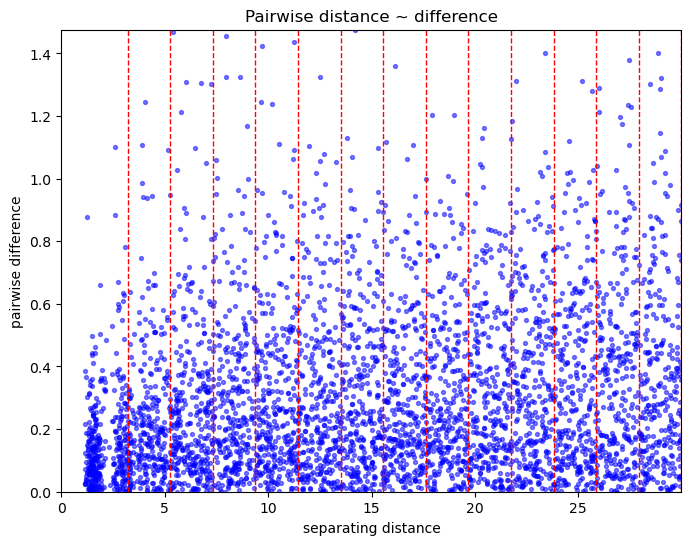

In [78]:
V.distance_difference_plot();

In [79]:
print("Spherical model rmse: ", sph_rmse)
print("Spherical eff. range: ", sph_eff_range)

print("Gaussian model rmse: ", gauss_rmse)
print("Gaussian eff. range: ", gauss_eff_range)

Spherical model rmse:  0.009694195182882151
Spherical eff. range:  17.94670213810688
Gaussian model rmse:  0.009727215351544574
Gaussian eff. range:  14.453880892621891


## Variogram analysis with Geone. 

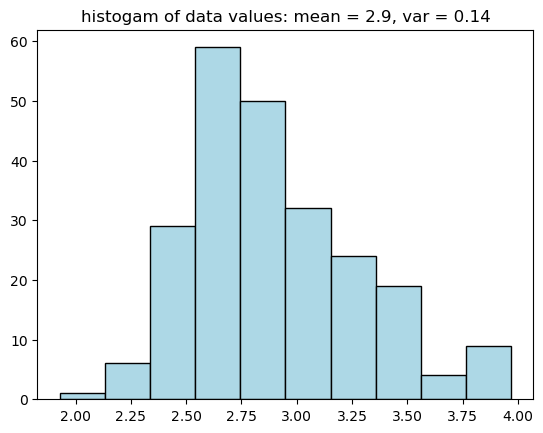

In [81]:
# plot the data and a histogram of its values. 

plt.hist(dhi, color ="lightblue", edgecolor = "black")
plt.title("histogam of data values: mean = {:.2g}, var = {:.2g}".format(np.mean(dhi), np.var(dhi)));

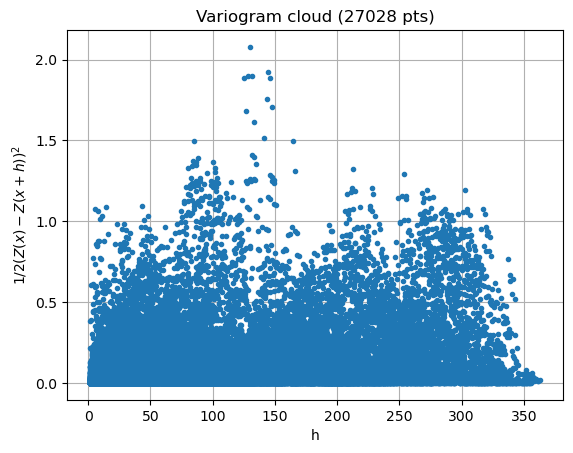

In [82]:
h, g, npair = geone.covModel.variogramCloud1D(x = curvilinear_coords[1:-1], v= dhi)

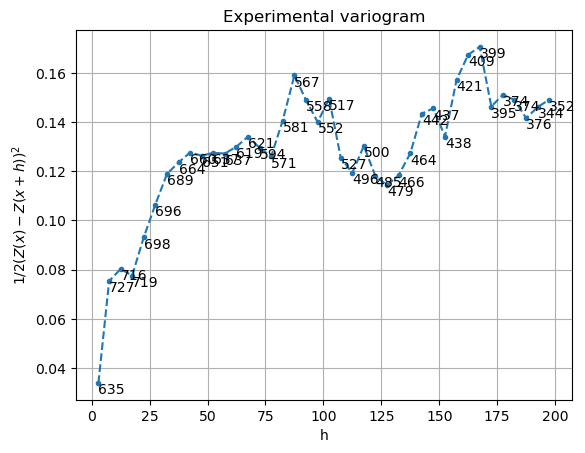

In [120]:
def make_vario_plot(descriptor):

    hexp, gexp, cexp = geone.covModel.variogramExp1D(x = df["curvilinear_coord"], v= df[descriptor], hmax = 200, ncla=40, make_plot=False);

    cov_model_to_optimise = geone.covModel.CovModel1D(
        elem=[
            ("exponential", {"w": np.nan, "r": np.nan}),
            ("nugget", {"w":np.nan})
            ], name = "")

    cov_model_opt, popt = geone.covModel.covModel1D_fit(df["curvilinear_coord"],  df[descriptor],
                                                        cov_model_to_optimise,
                                                        hmax=200,
                                                        bounds = ([ 0, 0, 0], 
                                                                [20, 300, 20]),
                                                                make_plot= False)

    plt.figure(figsize=(10, 5))

    geone.covModel.plot_variogramExp1D(hexp, gexp, cexp, label ="vario exp")
    cov_model_opt.plot_model(vario=True, hmax=200, label="vario opt")
    plt.legend()
    plt.show();

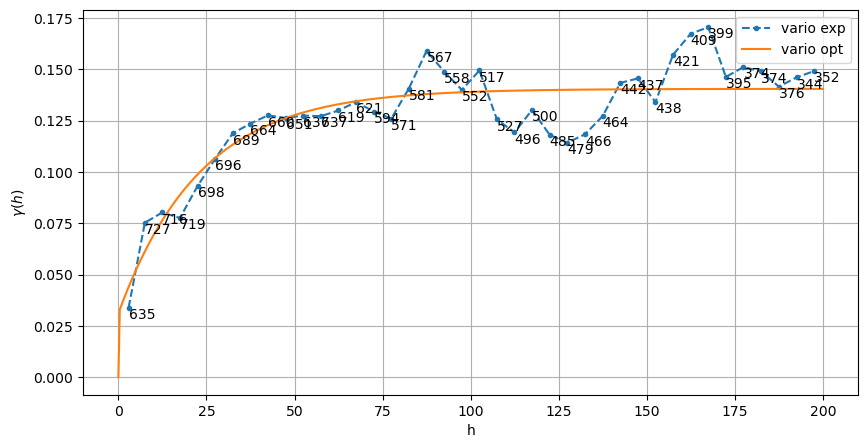

In [121]:
make_vario_plot("hydraulic_diameter")

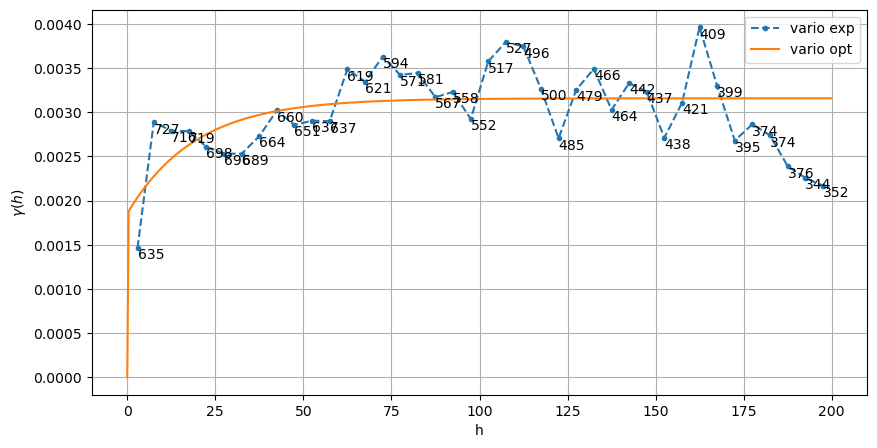

In [122]:
make_vario_plot("solidity")

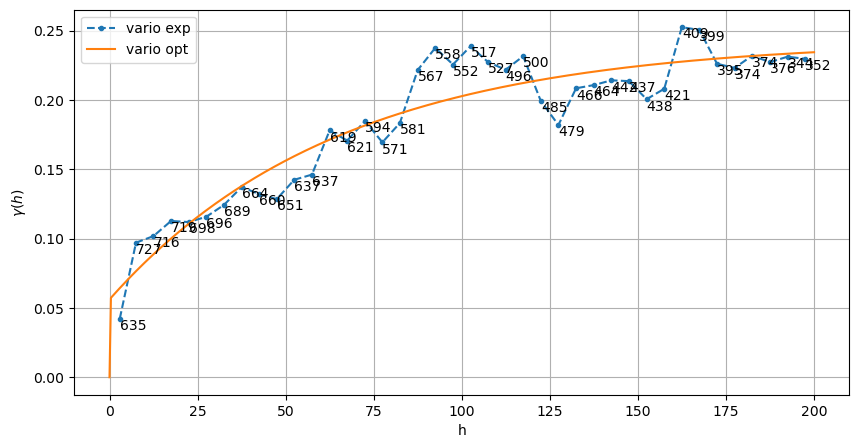

In [123]:
make_vario_plot("elongation")

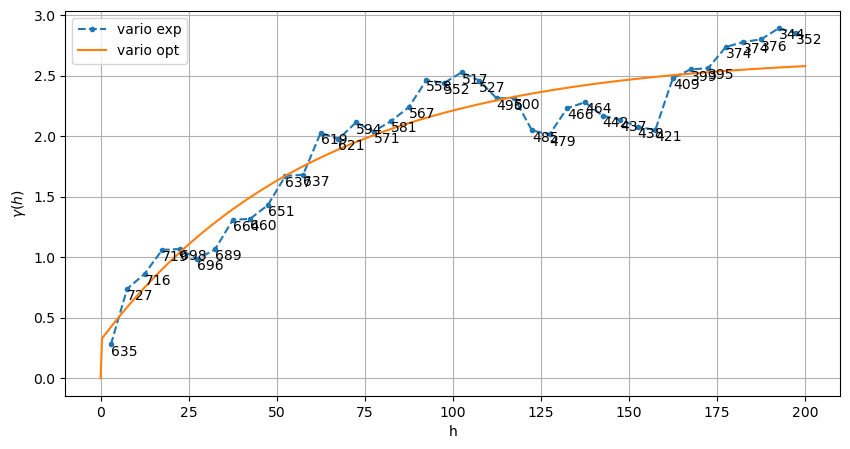

In [124]:
make_vario_plot("max_chord_length")